# EV Battery Failure: Model Training
## Goal
Compare classifiers, train the selected pipeline, calibrate probabilities, choose an alarm
threshold, and evaluate the frozen test split using the existing project implementation.

## Setup
Use a Python 3.11+ Jupyter kernel with `python -m pip install -e .` and
`python -m pip install notebook ipykernel` installed from the project root.
Run cells in order. This notebook is independent of the EDA notebook.

### Key assumptions
The dataset is simulated. No time-based forecasting claim is supported. Model selection uses
3-fold cross-validation on the 60% training partition, ranked by average precision (AP).
Separate 10% calibration and 10% threshold partitions precede the untouched 20% final test.
Do not change settings after inspecting final test scores.


In [1]:
from pathlib import Path
import sys

# Works when Jupyter starts in the data folder, project root, or parent folder.
cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "Ev_Battery_ML_Project"]
PROJECT_ROOT = next((p for p in candidates if (p / "src" / "evbattery").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Open this notebook from the EV battery project folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from evbattery.config import TARGET
from evbattery.data import load_dataset, split_data, make_features

DATA_PATH = PROJECT_ROOT / "data" / "ev_battery.csv"
BENCHMARK_ONLY = not DATA_PATH.is_file()
if BENCHMARK_ONLY:
    DATA_PATH = PROJECT_ROOT / "data" / "synthetic_benchmark.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError("Place ev_battery.csv in the project's data folder.")
RUN_NAME = "benchmark" if BENCHMARK_ONLY else "dataset"
display(Markdown(f"**Input:** `{DATA_PATH.name}`. " + (
    "**Benchmark demonstration only: these outputs are not results for the main dataset.**"
    if BENCHMARK_ONLY else "Simulated dataset; results do not establish real-vehicle forecasting.")))
df = load_dataset(DATA_PATH)
splits = split_data(df)
train = splits.train
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns")
get_ipython().run_line_magic("matplotlib", "inline")


**Input:** `synthetic_benchmark.csv`. **Benchmark demonstration only: these outputs are not results for the main dataset.**

Loaded 1,000 rows and 70 columns


## 1. Inspect reproducible partitions

In [2]:
split_table = pd.DataFrame([
    {"split": name, "rows": len(frame), "failures": int(frame[TARGET].sum()),
     "failure_rate": frame[TARGET].mean()}
    for name, frame in [("train", splits.train), ("calibration", splits.calibration),
                        ("threshold", splits.threshold), ("test", splits.test)]
])
display(split_table)
assert sum(split_table["rows"]) == len(df)

,split,rows,failures,failure_rate
0,train,600,199,0.331667
1,calibration,100,33,0.330000
2,threshold,100,33,0.330000
3,test,200,66,0.330000


## 2. Features and preprocessing
`make_features` performs per-row transformations and excludes the target, identifiers, suspect scores, and redundant columns. Numeric features use median imputation, missingness indicators, and scaling; categorical features use most-frequent imputation and one-hot encoding. All fitted transformations remain inside the CV pipeline.

In [3]:
from evbattery.config import IDENTIFIERS, SUSPECT_SCORES, REDUNDANT_EXACT
from evbattery.modeling import preprocessing, candidate_models
x_train = make_features(train)
y_train = train[TARGET].astype(int)
assert not set([TARGET, *IDENTIFIERS, *SUSPECT_SCORES, *REDUNDANT_EXACT]).intersection(x_train.columns)
display(pd.DataFrame({"feature": x_train.columns, "dtype": x_train.dtypes.astype(str).values}))
display(preprocessing(x_train))
display(pd.DataFrame([
    {"model": name, "estimator": type(model).__name__}
    for name, model in candidate_models().items()
]))

,feature,dtype
0,vehicle_brand,object
1,vehicle_model,object
2,vehicle_type,object
3,battery_manufacturer,object
4,battery_chemistry,object
...,...,...
58,cycles_per_year,float64
59,km_per_cycle,float64
60,fast_charge_power_stress,float64
61,prior_fault_and_warning_count,float64


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.0
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

,model,estimator
0,dummy_prior,DummyClassifier
1,logistic_regression,LogisticRegression
2,gaussian_naive_bayes,GaussianNB
3,sgd_logistic,SGDClassifier
4,decision_tree,DecisionTreeClassifier
5,random_forest,RandomForestClassifier
6,adaboost,AdaBoostClassifier
7,hist_gradient_boost,HistGradientBoostingClassifier


## 3. Training settings
The default compares all seven project classifiers plus the dummy reference. Full CV can take time. `BASELINE_ONLY=True` runs only logistic regression and the dummy; `FAST=True` is a smoke test, not a reportable comparison. An optional `CV_MAX_ROWS` (at least 1000) caps only training rows used for ranking; disclose this if enabled.

In [4]:
BASELINE_ONLY = False
FAST = False
CV_MAX_ROWS = None
OUTDIR = PROJECT_ROOT / "artifacts" / "notebooks" / RUN_NAME / "training"

## 4. Run model comparison and final training
`run_training` ranks models on training CV, fits the best non-dummy model on all training rows, applies sigmoid calibration on the calibration partition, chooses the F2-maximizing threshold on the threshold partition, and evaluates the test partition once. Reusing this function keeps notebook artifacts compatible with the project.

In [5]:
from evbattery.train import run_training
result = run_training(
    DATA_PATH, OUTDIR, fast=FAST, baseline_only=BASELINE_ONLY,
    cv_max_rows=CV_MAX_ROWS,
)
leaderboard = pd.DataFrame(result["leaderboard"])
display(leaderboard)
print("Selected model:", result["winner"])
print("Validation-selected threshold:", result["threshold"])

,model,cv_average_precision_mean,cv_average_precision_std,cv_roc_auc_mean,cv_roc_auc_std,fit_time_mean,score_time_mean
0,random_forest,0.810403,0.024800,0.894499,0.020001,0.157949,0.016462
1,gaussian_naive_bayes,0.789703,0.031890,0.881216,0.031655,0.012717,0.009034
2,hist_gradient_boost,0.770544,0.025468,0.892119,0.022914,0.129942,0.009824
3,adaboost,0.763468,0.031386,0.869330,0.028850,0.233888,0.017110
4,logistic_regression,0.741587,0.027707,0.856264,0.035133,0.041800,0.008629
5,sgd_logistic,0.723132,0.019427,0.842500,0.040015,0.019223,0.008503
6,decision_tree,0.668594,0.023294,0.814401,0.018028,0.019175,0.008987
7,dummy_prior,0.331667,0.002357,0.500000,0.000000,0.012069,0.008132


Selected model: random_forest
Validation-selected threshold: 0.29000000000000004


## 5. Cross-validation comparison
Error bars show fold standard deviations, not confidence intervals. AP summarizes precision and recall across thresholds.

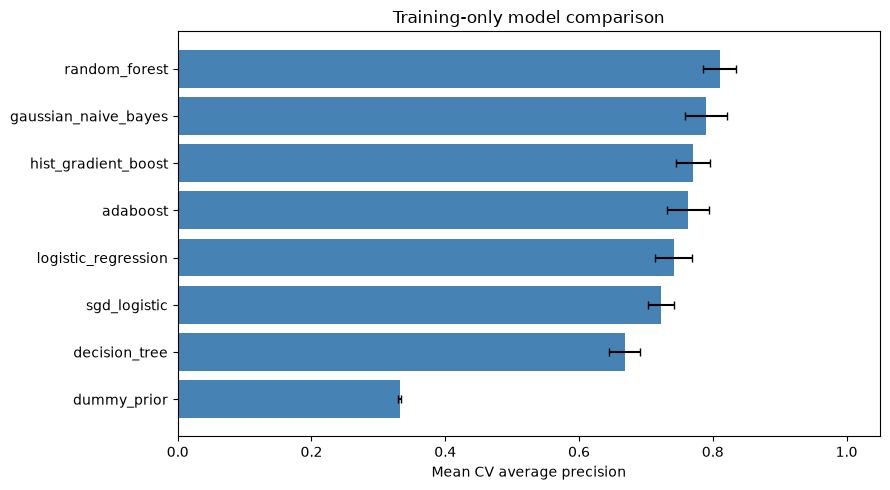

In [6]:
ranked = leaderboard.sort_values("cv_average_precision_mean")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(ranked["model"], ranked["cv_average_precision_mean"],
        xerr=ranked["cv_average_precision_std"], color="steelblue", capsize=3)
ax.set(xlabel="Mean CV average precision", title="Training-only model comparison", xlim=(0, 1.05))
plt.tight_layout()
plt.show()

## 6. Validation and final test results
Prioritize AP, recall, precision, F2, and false alarms. Test scores are for final reporting and must not guide model or threshold choices.

,threshold_validation,final_test
n,100.000000,200.000000
failures,33.000000,66.000000
threshold,0.290000,0.290000
average_precision,0.908688,0.806835
roc_auc,0.954319,0.910335
brier_score,0.076393,0.109197
precision,0.820513,0.716049
recall,0.969697,0.878788
f1,0.888889,0.789116
f2,0.935673,0.840580


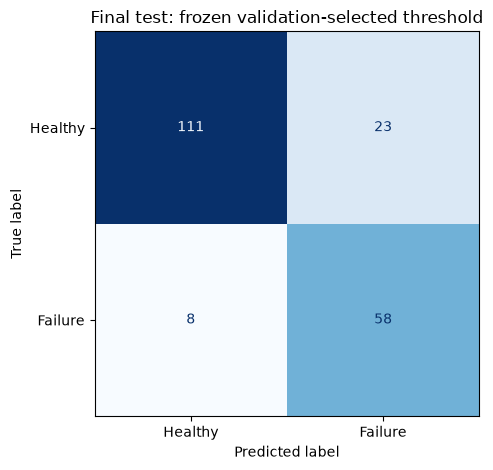

In [7]:
metrics = pd.DataFrame({
    "threshold_validation": result["threshold_metrics"],
    "final_test": result["test_metrics"],
})
display(metrics)
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay
m = result["test_metrics"]
ConfusionMatrixDisplay(
    np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]]),
    display_labels=["Healthy", "Failure"],
).plot(cmap="Blues", colorbar=False)
plt.title("Final test: frozen validation-selected threshold")
plt.tight_layout()
plt.show()

## 7. Saved model and reproducibility record
The model bundle includes preprocessing, calibrated classifier, threshold, and metadata. Load only trusted locally generated joblib files.

In [8]:
import json
metadata = json.loads((OUTDIR / "metadata.json").read_text(encoding="utf-8"))
display(pd.Series(metadata, name="value").to_frame())
display(pd.DataFrame({"file": sorted(p.name for p in OUTDIR.iterdir() if p.is_file())}))
display(Markdown(
    f"### Run summary\n"
    f"Input: `{DATA_PATH.name}`. Selected model: **{result['winner']}**. "
    f"Final test AP: **{m['average_precision']:.4f}**, recall: **{m['recall']:.4f}**, "
    f"precision: **{m['precision']:.4f}**, F2: **{m['f2']:.4f}**.\n\n"
    + ("**Benchmark demonstration only; do not quote as main-dataset performance.**"
       if BENCHMARK_ONLY else "Results apply to simulated rows, not validated real-vehicle forecasting.")
))
print(f"Saved artifacts: {OUTDIR}")

,value
created_utc,2026-11-23T08:48:02.134206+00:00
task,synthetic_EV_battery_failure_classification_NO...
training_data_sha256,a7a7493a02973efb31c76a5180abdf9b07222e474ef27a...
sklearn_version,1.8.0
numpy_version,2.4.6
pandas_version,2.3.3
winner,random_forest
seed,42
tuned_params,None
fast_smoke_test_only,False


,file
0,metadata.json
1,model.joblib
2,model_cv_leaderboard.csv
3,split_counts.csv
4,test_metrics.json
5,threshold_validation_metrics.json


### Run summary
Input: `synthetic_benchmark.csv`. Selected model: **random_forest**. Final test AP: **0.8068**, recall: **0.8788**, precision: **0.7160**, F2: **0.8406**.

**Benchmark demonstration only; do not quote as main-dataset performance.**

Saved artifacts: D:\5 th Sem project\Machine Learing Group Project\Ev_Battery_ML_Project\artifacts\notebooks\benchmark\training
